# Assignment 5B – K-Nearest Neighbours on Social Network Ads Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score
)

In [2]:
df = pd.read_csv('Social_Network_Ads.csv')
print(df.shape)
df.head()

(400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [27]:
# Encode Gender, drop User ID
df = df.drop(columns=['User ID'], errors='ignore')
le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])   # Male=1, Female=0

X = df[['Gender', 'Age', 'EstimatedSalary']].values
y = df['Purchased'].values

print("Class distribution of purchased:\n", pd.Series(y).value_counts())

Class distribution of purchased:
 0    257
1    143
Name: count, dtype: int64


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

Best k: 4


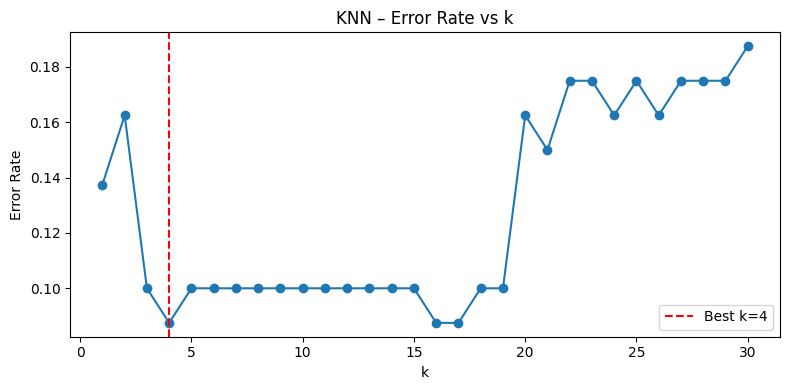

In [31]:
# Find optimal k using error rate curve
error_rates = []
k_range = range(1, 31)

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_s, y_train)
    error_rates.append(1 - accuracy_score(y_test, knn.predict(X_test_s)))

best_k = k_range[np.argmin(error_rates)]
print(f'Best k: {best_k}')

plt.figure(figsize=(8, 4))
plt.plot(k_range, error_rates, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k={best_k}')
plt.xlabel('k')
plt.ylabel('Error Rate')
plt.title('KNN – Error Rate vs k')
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
# Train with best k
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_s, y_train)
y_pred = knn.predict(X_test_s)

acc = accuracy_score(y_test, y_pred)
print(f'Accuracy : {acc:.4f}')
print(f'Error Rate: {1-acc:.4f}\n')
print(classification_report(y_test, y_pred, target_names=['Not Purchased', 'Purchased']))

Accuracy : 0.9125
Error Rate: 0.0875

               precision    recall  f1-score   support

Not Purchased       0.94      0.92      0.93        51
    Purchased       0.87      0.90      0.88        29

     accuracy                           0.91        80
    macro avg       0.90      0.91      0.91        80
 weighted avg       0.91      0.91      0.91        80



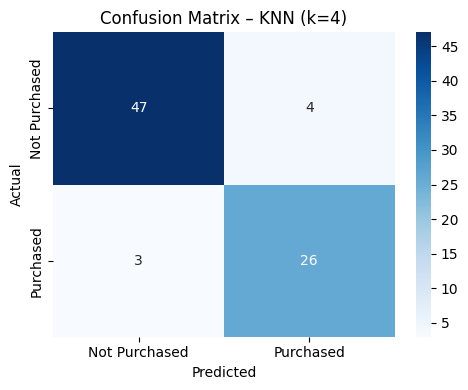

In [7]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Purchased', 'Purchased'],
            yticklabels=['Not Purchased', 'Purchased'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix – KNN (k={best_k})')
plt.tight_layout()
plt.show()

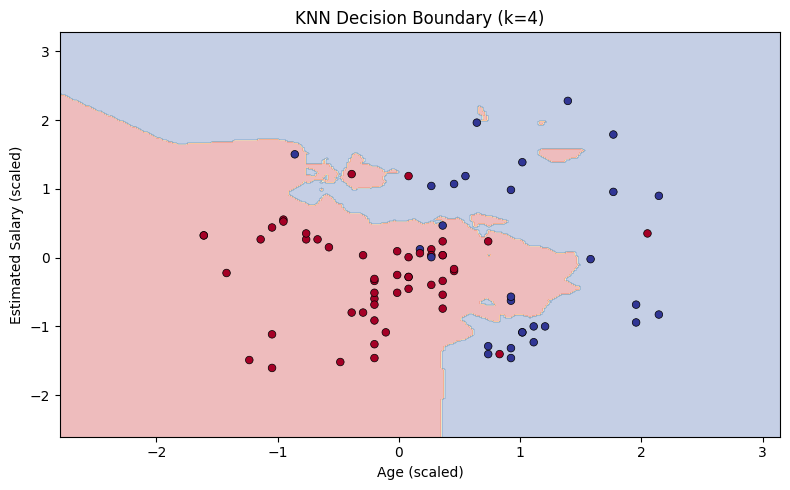

In [33]:
# Decision boundary – Age vs EstimatedSalary (2D)
X2 = df[['Age', 'EstimatedSalary']].values
y2 = df['Purchased'].values

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2)
sc2 = StandardScaler()
X2_train_s = sc2.fit_transform(X2_train)
X2_test_s  = sc2.transform(X2_test)

knn2 = KNeighborsClassifier(n_neighbors=best_k)
knn2.fit(X2_train_s, y2_train)

h = 0.02
x_min, x_max = X2_train_s[:, 0].min()-1, X2_train_s[:, 0].max()+1
y_min, y_max = X2_train_s[:, 1].min()-1, X2_train_s[:, 1].max()+1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))
Z = knn2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='RdYlBu')
plt.scatter(X2_test_s[:, 0], X2_test_s[:, 1], c=y2_test,
            cmap='RdYlBu', edgecolors='k', linewidths=0.5, s=30)
plt.xlabel('Age (scaled)')
plt.ylabel('Estimated Salary (scaled)')
plt.title(f'KNN Decision Boundary (k={best_k})')
plt.tight_layout()
plt.show()